# 02. Phase A Baseline: Frozen 3D MedicalNet ResNet-18 + Siamese Multi-Scale Temporal Difference Decoder

In **Phase A**, we evaluate how well a **100% frozen pretrained 3D MedicalNet ResNet-18** backbone (with 1-to-4 channel weight inflation across `[FLAIR, MPRAGE, T2, PD]`) performs when paired with our **Siamese Multi-Scale Temporal Difference Decoder (`SiameseLongitudinalUNet3D`)**.

- **Inputs:** Co-registered 4-channel 3D scans $(x_{t_1}, x_{t_2})$ and normalized visit interval $\Delta t = (t_2 - t_1) / 4.0$ (no baseline mask $M_{t_1}$ is passed as input).
- **Target:** Evolved 3D lesion mask $\hat{M}_{t_2}$, evaluated on full brain volumes ($181\times 217\times 181$) via Gaussian-blended 3D `sliding_window_inference`.

In [1]:
!git clone https://github.com/edupras/simclr-ms-mri.git

Cloning into 'simclr-ms-mri'...
remote: Enumerating objects: 49, done.
remote: Counting objects: 100% (49/49), done.
remote: Compressing objects: 100% (46/46), done.
remote: Total 49 (delta 9), reused 34 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (49/49), 836.03 KiB | 32.15 MiB/s, done.
Resolving deltas: 100% (9/9), done.


In [2]:
# 1. Mount Google Drive & Setup Environment (Colab Pro A100)
import json
import sys
from pathlib import Path

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'monai>=1.3.0', 'nibabel>=5.0.0', 'pyyaml', 'tqdm'])

REPO_CANDIDATES = [
    Path('/content/drive/MyDrive/masters/simclr-ms-mri'),
    Path('/content/simclr-ms-mri'),
    Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd(),
]
for candidate in REPO_CANDIDATES:
    if (candidate / 'src').exists():
        PROJECT_ROOT = candidate.resolve()
        if str(PROJECT_ROOT) not in sys.path:
            sys.path.insert(0, str(PROJECT_ROOT))
        break

import torch
from torch.utils.data import DataLoader

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {DEVICE} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"})')

Mounted at /content/drive
Using device: cuda (NVIDIA L4)


In [3]:
# 2. Build Zero-Leakage LOPO Fold Split & Preload Volumes into System RAM
from src.utils.config import load_config, set_deterministic_seed
from src.data.isbi_dataset import discover_isbi2015_visits, get_lopo_fold_splits
from src.data.transforms import InMemoryVolumeCache, LongitudinalSegmentationPatchDataset

cfg = load_config(PROJECT_ROOT / 'configs' / 'default.yaml')
set_deterministic_seed(cfg['project']['seed'])

FOLD_IDX = 0  # Held-out validation subject for Fold 0 (set loop 0..4 for full 5-fold CV)
patient_visits = discover_isbi2015_visits(cfg['data']['root_dir'], modalities=cfg['data']['modalities'])
split = get_lopo_fold_splits(patient_visits, fold_idx=FOLD_IDX, max_time_gap_norm=cfg['data']['max_time_gap_norm'])
split.verify_zero_leakage()

print(f'Fold {FOLD_IDX} | Held-out Val Subject: {split.val_patient_id} ({len(split.seg_val_pairs)} pairs)')
print(f'Supervised Train Subjects: {split.train_labeled_patient_ids} ({len(split.seg_train_pairs)} pairs)')

volume_cache = InMemoryVolumeCache(
    modalities=cfg['data']['modalities'],
    target_rater=cfg['data']['target_rater'],
    enabled=(cfg['data']['cache_rate'] > 0),
)
labeled_visits = [v for pid in split.train_labeled_patient_ids + [split.val_patient_id] for v in patient_visits[pid]]
volume_cache.preload_visits(labeled_visits)
print(f'Preloaded {len(labeled_visits)} labeled 3D multi-modality visits into system RAM.')

train_seg_ds = LongitudinalSegmentationPatchDataset(
    pairs=split.seg_train_pairs,
    volume_cache=volume_cache,
    patch_size=tuple(cfg['data']['patch_size']),
    patches_per_pair=cfg['data']['patches_per_pair_seg'],
    pos_neg_ratio=cfg['data']['pos_neg_ratio'],
    augment=True,
)
train_seg_loader = DataLoader(
    train_seg_ds,
    batch_size=cfg['segmentation']['batch_size'],
    shuffle=True,
    num_workers=cfg['data']['num_workers'],
    pin_memory=True,
)

Fold 0 | Held-out Val Subject: training01 (6 pairs)
Supervised Train Subjects: ['training02', 'training03', 'training04', 'training05'] (28 pairs)
Preloaded 21 labeled 3D multi-modality visits into system RAM.


In [4]:
# 3. Initialize Frozen Pretrained 3D MedicalNet ResNet-18 + Siamese Temporal-Difference Decoder
from src.models.backbone import MedicalNet3DResNet18
from src.models.segmentation_decoder import SiameseLongitudinalUNet3D
from src.losses.segmentation_loss import EvolutionWeightedDiceFocalLoss

backbone_phase_a = MedicalNet3DResNet18(
    in_channels=cfg['backbone']['in_channels'],
    pretrained=cfg['backbone']['pretrained'],
)
backbone_phase_a.freeze_all()

model_phase_a = SiameseLongitudinalUNet3D(
    backbone=backbone_phase_a,
    decoder_channels=tuple(cfg['segmentation']['decoder_channels']),
    freeze_backbone=True,
).to(DEVICE)

enc_stats = model_phase_a.backbone.count_trainable_parameters()
total_trainable = sum(p.numel() for p in model_phase_a.parameters() if p.requires_grad)
print(f"Backbone Trainable Params: {enc_stats['trainable']:,} / {enc_stats['total']:,} (100% Frozen)")
print(f'Decoder Trainable Params:  {total_trainable:,}')

Backbone Trainable Params: 0 / 33,052,032 (100% Frozen)
Decoder Trainable Params:  7,834,977


In [5]:
# 4. Train Phase A Decoder with A100 BFloat16 Mixed Precision & Full-Volume Sliding-Window Validation
from src.engine.trainer import train_segmentation_epoch
from src.engine.evaluator import evaluate_lopo_validation_pairs

criterion = EvolutionWeightedDiceFocalLoss(
    dice_weight=cfg['segmentation']['dice_weight'],
    focal_weight=cfg['segmentation']['focal_weight'],
    change_voxel_weight=cfg['segmentation']['change_voxel_weight'],
)
optimizer = torch.optim.AdamW(
    [p for p in model_phase_a.parameters() if p.requires_grad],
    lr=cfg['segmentation']['lr_decoder'],
    weight_decay=cfg['segmentation']['weight_decay'],
)
epochs = cfg['segmentation']['epochs']
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

OUTPUT_DIR = Path(cfg['project']['output_dir'])
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
best_ckpt_path = OUTPUT_DIR / f'phase_a_fold{FOLD_IDX}_best.pt'

best_val_dice = -1.0
best_val_summary = {}

for epoch in range(1, epochs + 1):
    train_metrics = train_segmentation_epoch(
        model=model_phase_a,
        dataloader=train_seg_loader,
        criterion=criterion,
        optimizer=optimizer,
        device=DEVICE,
        use_amp=cfg['segmentation']['use_amp'],
        amp_dtype_str=cfg['segmentation']['amp_dtype'],
    )
    scheduler.step()

    if epoch % 5 == 0 or epoch == epochs:
        val_summary, _ = evaluate_lopo_validation_pairs(
            model=model_phase_a,
            val_pairs=split.seg_val_pairs,
            volume_cache=volume_cache,
            device=DEVICE,
            roi_size=tuple(cfg['data']['patch_size']),
            sw_batch_size=cfg['segmentation']['sw_batch_size'],
            overlap=cfg['segmentation']['sw_overlap'],
            threshold=cfg['segmentation']['threshold'],
            use_amp=cfg['segmentation']['use_amp'],
            amp_dtype_str=cfg['segmentation']['amp_dtype'],
        )
        print(
            f"[Epoch {epoch:02d}/{epochs:02d}] Train Loss: {train_metrics['loss']:.4f} | "
            f"Val Full-3D t2 Dice: {val_summary['t2_dice']:.4f} | "
            f"New/Enlarging Dice: {val_summary['new_enlarging_dice']:.4f} | "
            f"ΔVol MAE: {val_summary['delta_vol_mae_ml']:.3f} mL"
        )
        if val_summary['t2_dice'] > best_val_dice:
            best_val_dice = val_summary['t2_dice']
            best_val_summary = val_summary
            torch.save(model_phase_a.state_dict(), best_ckpt_path)

metrics_path = OUTPUT_DIR / f'phase_a_fold{FOLD_IDX}_metrics.json'
with metrics_path.open('w') as f:
    json.dump(best_val_summary, f, indent=2)
print(f'\nSaved best Phase A model to {best_ckpt_path} (Best Val t2 Dice = {best_val_dice:.4f})')

[Epoch 05/50] Train Loss: 0.7757 | Val Full-3D t2 Dice: 0.4695 | New/Enlarging Dice: 0.1602 | ΔVol MAE: 21.219 mL
[Epoch 10/50] Train Loss: 0.4497 | Val Full-3D t2 Dice: 0.6205 | New/Enlarging Dice: 0.2858 | ΔVol MAE: 2.721 mL
[Epoch 15/50] Train Loss: 0.3008 | Val Full-3D t2 Dice: 0.6981 | New/Enlarging Dice: 0.3718 | ΔVol MAE: 3.008 mL
[Epoch 20/50] Train Loss: 0.2423 | Val Full-3D t2 Dice: 0.7302 | New/Enlarging Dice: 0.4115 | ΔVol MAE: 4.079 mL
[Epoch 25/50] Train Loss: 0.2320 | Val Full-3D t2 Dice: 0.6579 | New/Enlarging Dice: 0.3577 | ΔVol MAE: 7.023 mL
[Epoch 30/50] Train Loss: 0.2044 | Val Full-3D t2 Dice: 0.7331 | New/Enlarging Dice: 0.3905 | ΔVol MAE: 4.931 mL
[Epoch 35/50] Train Loss: 0.1931 | Val Full-3D t2 Dice: 0.6966 | New/Enlarging Dice: 0.3692 | ΔVol MAE: 6.234 mL
[Epoch 40/50] Train Loss: 0.1969 | Val Full-3D t2 Dice: 0.7394 | New/Enlarging Dice: 0.4075 | ΔVol MAE: 4.420 mL
[Epoch 45/50] Train Loss: 0.1862 | Val Full-3D t2 Dice: 0.7281 | New/Enlarging Dice: 0.4057 | Δ

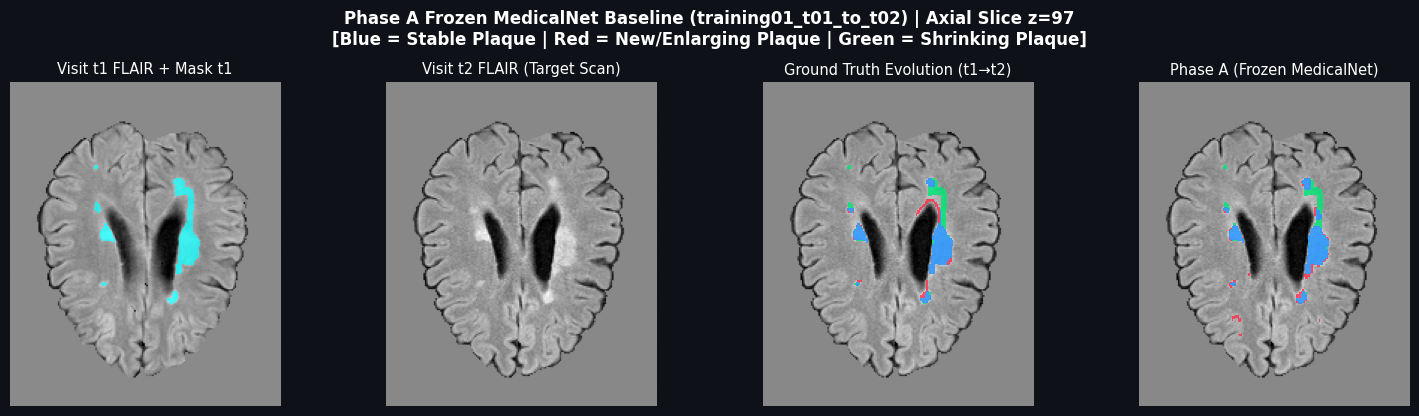

In [6]:
# 5. Visualize Phase A Full-Volume 3D Lesion Evolution Prediction on Held-Out Patient
import matplotlib.pyplot as plt
from src.engine.evaluator import predict_full_volume_pair
from src.utils.visualization import plot_lesion_evolution_comparison

model_phase_a.load_state_dict(torch.load(best_ckpt_path, map_location=DEVICE))
val_pair = split.seg_val_pairs[0]
d1 = volume_cache.get_visit_data(val_pair.visit_t1)
d2 = volume_cache.get_visit_data(val_pair.visit_t2)

pred_out = predict_full_volume_pair(
    model=model_phase_a,
    vol_t1=d1['image'],
    vol_t2=d2['image'],
    delta_t_norm=val_pair.delta_t_norm,
    device=DEVICE,
    roi_size=tuple(cfg['data']['patch_size']),
    sw_batch_size=cfg['segmentation']['sw_batch_size'],
    overlap=cfg['segmentation']['sw_overlap'],
)

fig = plot_lesion_evolution_comparison(
    flair_t1=d1['image'][0],
    flair_t2=d2['image'][0],
    gt_mask_t1=d1['mask'],
    gt_mask_t2=d2['mask'],
    pred_phase_a_t2=pred_out['pred_mask_t2'],
    patient_pair_title=f'Phase A Frozen MedicalNet Baseline ({val_pair.pair_id})',
)
plt.show()